# Análise exploratória do histórico musical

Objetivo: conhecer a estrutura e a qualidade dos dados e explorar
os padrões de escuta por artista, gênero, país, dia e horário.

Cada linha deve representar uma escuta.

In [1]:
from pathlib import Path

import pandas as pd

In [2]:
caminho = Path('../../data/processed/data_final.csv')

print(caminho.exists())

True


In [3]:
df = pd.read_csv(caminho)

df.head(5)

,artist_name,album_name,scrobble_date,music_name,artist_mbid,date,time,week_day,week_day_id,group_hour,type,name,gender,country,area.type,area.name,query_name,legal_name,music_genre
0,Troye Sivan,She’s the Best,2026-10-19 14:01:03-03:00,Le Boy,e5712ceb-c37a-4c49-a11c-ccf4e21852d4,2026-10-19,14:01:03,Monday,0,14,Person,Troye Sivan,male,AU,Country,Australia,Troye Sivan,Troye Sivan Mellet,pop
1,Troye Sivan,She’s the Best,2026-10-19 13:57:27-03:00,emBARRAssingly,e5712ceb-c37a-4c49-a11c-ccf4e21852d4,2026-10-19,13:57:27,Monday,0,13,Person,Troye Sivan,male,AU,Country,Australia,Troye Sivan,Troye Sivan Mellet,pop
2,Troye Sivan,She’s the Best,2026-10-19 13:53:54-03:00,Cowboy,e5712ceb-c37a-4c49-a11c-ccf4e21852d4,2026-10-19,13:53:54,Monday,0,13,Person,Troye Sivan,male,AU,Country,Australia,Troye Sivan,Troye Sivan Mellet,pop
3,Tinashe,POPSTAR,2026-10-18 17:37:00-03:00,POPSTAR,396a9525-0994-4542-b480-c4587feeb476,2026-10-18,17:37:00,Sunday,6,17,Person,Tinashe,female,US,Country,United States,Tinashe,Tinashe Jorgenson Kachingwe,pop
4,Mollie Elizabeth,Run Rabbit,2026-10-18 16:27:43-03:00,Run Rabbit,adef6e0a-0610-45df-8a17-55aa92a47c15,2026-10-18,16:27:43,Sunday,6,16,Person,Mollie Elizabeth,female,unregistered,Subdivision,Washington,Mollie Elizabeth,unregistered,pop


In [4]:
df.columns.tolist()

['artist_name',
 'album_name',
 'scrobble_date',
 'music_name',
 'artist_mbid',
 'date',
 'time',
 'week_day',
 'week_day_id',
 'group_hour',
 'type',
 'name',
 'gender',
 'country',
 'area.type',
 'area.name',
 'query_name',
 'legal_name',
 'music_genre']

In [5]:
print(df.shape[0])
print(df.shape[1])

1411
19


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1411 entries, 0 to 1410
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   artist_name    1411 non-null   str  
 1   album_name     1411 non-null   str  
 2   scrobble_date  1411 non-null   str  
 3   music_name     1411 non-null   str  
 4   artist_mbid    1411 non-null   str  
 5   date           1411 non-null   str  
 6   time           1411 non-null   str  
 7   week_day       1411 non-null   str  
 8   week_day_id    1411 non-null   int64
 9   group_hour     1411 non-null   int64
 10  type           1411 non-null   str  
 11  name           1411 non-null   str  
 12  gender         1411 non-null   str  
 13  country        1411 non-null   str  
 14  area.type      1411 non-null   str  
 15  area.name      1411 non-null   str  
 16  query_name     1411 non-null   str  
 17  legal_name     1411 non-null   str  
 18  music_genre    1411 non-null   str  
dtypes: int64(2), str(

In [7]:
df['artist_mbid'].isna().sum()

np.int64(0)

In [9]:
sem_mbid = df["artist_mbid"].isna()

print("Escutas sem MBID:", sem_mbid.sum())

print(
    "Artistas distintos nessas escutas:",
    df.loc[sem_mbid, "artist_name"].nunique()
)

Escutas sem MBID: 0
Artistas distintos nessas escutas: 0


In [10]:
df.loc[sem_mbid, "artist_name"].value_counts()

Series([], Name: count, dtype: int64)

## Artistas mais ouvidos

- Quais artistas têm mais escutas?
- Qual percentual do histórico está concentrado nos dez primeiros?

In [ ]:
#   Contando escutas por artistas
escutas_por_artista = (
    df["artist_name"]
    .value_counts() # quantas vezes cada valor apartece e ordena mais frequente
    .rename_axis("artista") # renomeia o indice
    .reset_index(name="escutas") # 
)

escutas_por_artista.head(10) # cada linha da tabela representa uma escuta

,artista,escutas
0,Olivia Rodrigo,192
1,Troye Sivan,125
2,ADÉLA,81
3,Sabrina Carpenter,44
4,Taylor Swift,42
5,Ariana Grande,41
6,BTS,36
7,George Michael,26
8,f5ve,24
9,O Rappa,24


In [13]:
escutas_por_artista["percentual"] = (
    escutas_por_artista["escutas"] / len(df) * 100 
)

escutas_por_artista.head(10).round({"percentual": 2}) # faz arredondamento somente visual

,artista,escutas,percentual
0,Olivia Rodrigo,192,13.61
1,Troye Sivan,125,8.86
2,ADÉLA,81,5.74
3,Sabrina Carpenter,44,3.12
4,Taylor Swift,42,2.98
5,Ariana Grande,41,2.91
6,BTS,36,2.55
7,George Michael,26,1.84
8,f5ve,24,1.70
9,O Rappa,24,1.70


In [14]:
participacao_top10 = (
    escutas_por_artista.head(10)["percentual"].sum()
)

print(
    f"Os dez artistas mais ouvidos representam "
    f"{participacao_top10:.1f}% das escutas."
)

print(
    f"Quantidade de nomes de artistas distintos: "
    f"{df['artist_name'].nunique()}"
)

Os dez artistas mais ouvidos representam 45.0% das escutas.
Quantidade de nomes de artistas distintos: 233


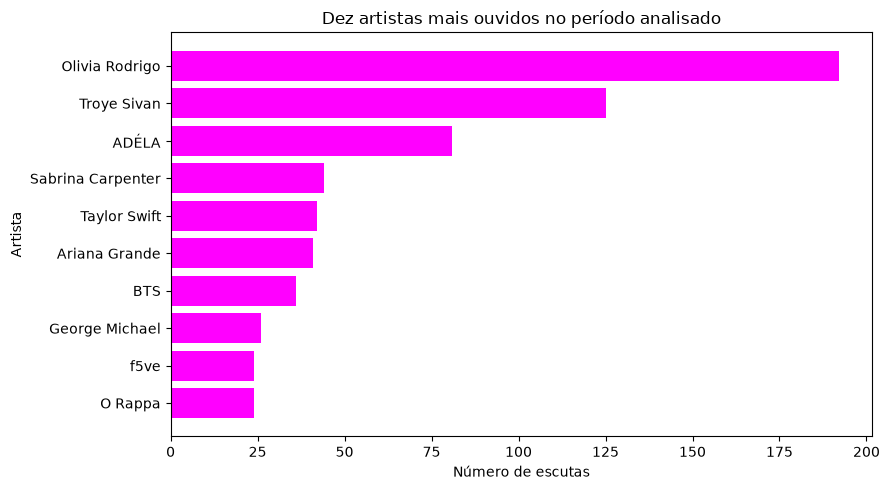

In [17]:
import matplotlib.pyplot as plt

top10 = escutas_por_artista.head(10)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(top10["artista"], top10["escutas"], color = 'magenta')
ax.invert_yaxis()

ax.set_title("Dez artistas mais ouvidos no período analisado")
ax.set_xlabel("Número de escutas")
ax.set_ylabel("Artista")

plt.tight_layout()
plt.show()


#### Observações

- O artista mais escutado foi Olivia Rodrigo (análise feita em 20/10/2026)
- Representa: 13,61% do total de histórico
- o top 10 mais escutados representam 45% da amostra


conclusão: 
No período analisado, os três artistas mais ouvidos foram Olivia Rodrigo, Troye Sivan e ADÉLA, com destaque para Olivia Rodrigo. 
Entre os demais integrantes do top 10, as quantidades de escutas são menores e mais próximas entre si.

In [18]:
# Medindo concentração em relação ao eixo completo
percentual_top3 = (
    escutas_por_artista.head(3)["escutas"].sum()
    / len(df)
    * 100
)

print(
    f"Os três primeiros artistas concentram "
    f"{percentual_top3:.1f}% de todas as escutas."
)

Os três primeiros artistas concentram 28.2% de todas as escutas.


## Músicas mais ouvidas

- Quais músicas têm mais escutas?
- Os artistas mais ouvidos também aparecem entre as faixas mais repetidas?

In [ ]:
escutas_por_musica = (
    df.groupby(["artist_name", "music_name"]) # -> todas as musicas do mesmo artista ficam agrupadas em grupos
    .size() # conta quantas linhas tem em cada grupo
    .reset_index(name="escutas") # índice vira colunas normais, escutas é a contagem
    .sort_values("escutas", ascending=False) # ordena decrescente
    .reset_index(drop=True) # reseta o índice
) # o número de linhas em cada montinho é o número de vezes que a música foi ouvida.

escutas_por_musica.head(10)

,artist_name,music_name,escutas
0,Olivia Rodrigo,serena joy,29
1,Olivia Rodrigo,honeybee,27
2,Sabrina Carpenter,Sugar Talking,26
3,George Michael,Cowboys And Angels - 2010 Remastered Version,26
4,O Rappa,Anjos (Pra Quem Tem Fé),23
5,f5ve,I Choose You,22
6,ADÉLA,NICOLE KIDMAN,20
7,t.A.T.u.,All the Things She Said,17
8,Troye Sivan,Bloom - Recorded At Spotify Studios NYC,15
9,Olivia Rodrigo,maggots for brains,15


In [20]:
escutas_por_musica["percentual"] = (
    escutas_por_musica["escutas"] / len(df) * 100
)

escutas_por_musica.head(10).round({"percentual": 2})

,artist_name,music_name,escutas,percentual
0,Olivia Rodrigo,serena joy,29,2.06
1,Olivia Rodrigo,honeybee,27,1.91
2,Sabrina Carpenter,Sugar Talking,26,1.84
3,George Michael,Cowboys And Angels - 2010 Remastered Version,26,1.84
4,O Rappa,Anjos (Pra Quem Tem Fé),23,1.63
5,f5ve,I Choose You,22,1.56
6,ADÉLA,NICOLE KIDMAN,20,1.42
7,t.A.T.u.,All the Things She Said,17,1.20
8,Troye Sivan,Bloom - Recorded At Spotify Studios NYC,15,1.06
9,Olivia Rodrigo,maggots for brains,15,1.06


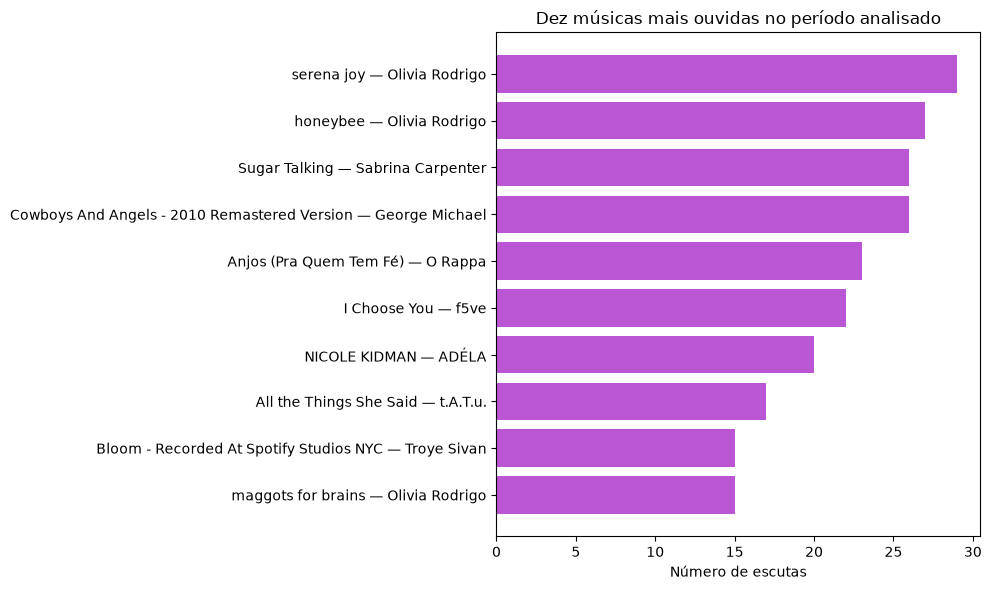

In [27]:
top10_musicas = escutas_por_musica.head(10).copy()

top10_musicas["rotulo"] = (
    top10_musicas["music_name"]
    + " — "
    + top10_musicas["artist_name"]
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top10_musicas["rotulo"],
    top10_musicas["escutas"],
    color="mediumorchid"
)

ax.invert_yaxis()

ax.set_title("Dez músicas mais ouvidas no período analisado")
ax.set_xlabel("Número de escutas")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


Observe:
- Uma faixa se destaca muito das outras?
- Um mesmo artista aparece várias vezes?
- Olivia Rodrigo, Troye Sivan e ADÉLA também dominam esse ranking?

#### trocar gráfico e responder análises